##### __Датасет частини 1__: "Tatoeba: English - Norwegian Nynorsk"
##### __Посилання на датасет__: https://www.manythings.org/anki/
##### __Опис датасету__: 5 451 пара коротких речень: англійське речення та його переклад оригінальною норвежською.

##### __Датасет частини 2б__: "MovieLens Latest Datasets" (ml-latest-small), той самий, що в лабораторній роботі 2
##### __Посилання на датасет__: https://grouplens.org/datasets/movielens/latest/
##### __Опис датасету__: теги користувачів (`tags.csv`) як тексти та жанри фільмів (`movies.csv`) як класи. Тестова вибірка, класи та метрики такі самі, як у лабораторній роботі 2.

##### __Датасет частини 3б__: "Oxford-IIIT Pet"
##### __Посилання на датасет__: https://www.robots.ox.ac.uk/~vgg/data/pets/
##### __Опис датасету__: 7 349 фотографій котів і собак 37 порід. Датасети лабораторної роботи 2 (таблиця й теги) зображень не містять, тому для частини 3б взято цей набір.

#### __Мета роботи__: Ознайомитися з архітектурою Transformer та з типовими способами її використання: реалізувати encoder-decoder для машинного перекладу з нуля, застосувати готові претреновані моделі (pipeline та fine-tuning) для текстів, а також попрацювати з моделями для зображень (генерація за текстом і вектори ознак); порівняти fine-tuning трансформера з класичним алгоритмом із лабораторної роботи 2.

# Частина 1. Машинний переклад: Transformer (encoder-decoder), написаний з нуля

##### Постановка задачі

Перекласти речення з англійської на нюношк (одна з двох форм норвезької мови). Механізм уваги, feed-forward шари, encoder і decoder реалізовано вручну на PyTorch, готові класи `nn.Transformer*` не використовуються.

Дані невеликі: близько 4000 навчальних пар. Тому мета в тому, щоб зрозуміти, як влаштований трансформер, і побачити, що він вивчає на малому обсязі даних.

In [3]:
import re
import random
import math
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import Counter
from torch.utils.data import Dataset, DataLoader

random.seed(10)
torch.manual_seed(10)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


In [4]:
lines = open('nno-eng/nno.txt', encoding='utf-8').read().split('\n')

pairs = []
seen = set()
total_lines = 0
for line in lines:
    parts = line.split('\t')
    if len(parts) < 2:
        continue
    total_lines = total_lines + 1
    eng = parts[0].strip()
    nno = parts[1].strip()
    if eng in seen:
        continue
    seen.add(eng)
    pairs.append((eng, nno))

print('Пар у файлі:', total_lines)
print('Унікальних англійських речень:', len(pairs))
print()
for i in range(5):
    print(random.choice(pairs))

Пар у файлі: 5451
Унікальних англійських речень: 4504

('Tom got fat.', 'Tom vart tjukk.')
('Tom sometimes speaks French.', 'Tom snakkar av og til fransk.')
("Why don't you answer my question?", 'Korfor svarer du ikkje på spørsmålet mitt?')
('Choose one.', 'Vel ein.')
('Tom began to drink.', 'Tom begynte å drikka.')


##### Датасет та дублікати

У файлі 5 451 рядок, але унікальних англійських речень лише 4 504. У Tatoeba до одного англійського речення часто прив'язано кілька перекладів від різних авторів. У код додано `seen`: з кожної групи залишається перший переклад.

Це потрібно не лише для чистоти даних. Якби те саме англійське речення з різними перекладами потрапило і в train, і в val, то модель «перевірялася» б на реченні, яке вже бачила, і оцінка була б завищеною. Третій стовпець (автори) не використовується.

Випадкові приклади показують, що речення короткі й розмовні, з частими іменами Tom і Mary. Повторювані шаблони модель вивчить добре, а рідкісні слова погано.

In [5]:
def tokenize(text):
    return re.findall(r'\w+|[^\w\s]', text.lower())

eng_lengths = [len(tokenize(p[0])) for p in pairs]
nno_lengths = [len(tokenize(p[1])) for p in pairs]

print('Найдовше речення English (токенів):', max(eng_lengths))
print('Найдовше речення Nynorsk (токенів):', max(nno_lengths))

MAX_WORDS = 15
short_count = 0
for i in range(len(pairs)):
    if eng_lengths[i] <= MAX_WORDS and nno_lengths[i] <= MAX_WORDS:
        short_count = short_count + 1
print('Пар, у яких обидва речення не довші за', MAX_WORDS, 'токенів:', short_count, 'з', len(pairs))

Найдовше речення English (токенів): 21
Найдовше речення Nynorsk (токенів): 18
Пар, у яких обидва речення не довші за 15 токенів: 4487 з 4504


In [6]:
pairs = [p for p in pairs if len(tokenize(p[0])) <= MAX_WORDS and len(tokenize(p[1])) <= MAX_WORDS]

random.shuffle(pairs)
train_size = int(0.9 * len(pairs))
train_pairs = pairs[:train_size]
val_pairs = pairs[train_size:]

print('Train:', len(train_pairs))
print('Val:', len(val_pairs))

Train: 4038
Val: 449


##### Токенізація, довжина речень і розбиття вибірки

`tokenize` переводить текст у нижній регістр і розрізає його регулярним виразом на слова та окремі знаки пунктуації, тому `?` і `.` стають окремими токенами. Побічний ефект: усі переклади далі будуть малими літерами, і модель не розрізняє `Tom` та `tom`.

Найдовше речення має 21 токен (English) та 18 (Nynorsk), але пар, де обидва речення не довші за 15 токенів, 4 487 з 4 504, тобто 99.6%.

Розбиття 90 / 10: Train 4 038 / Val 449. Окремого test немає, і це припустимо, оскільки кількість епох (30) задано заздалегідь і за val не підбиралася.

In [7]:
MAX_LEN = MAX_WORDS + 2
specials = ['[PAD]', '[UNK]', '[BOS]', '[EOS]']


def build_vocab(sentences):
    counter = Counter()
    for s in sentences:
        counter.update(tokenize(s))
    itos = specials + [w for w, c in counter.most_common()]
    stoi = {w: i for i, w in enumerate(itos)}
    return stoi, itos


eng_stoi, eng_itos = build_vocab([p[0] for p in train_pairs])
nno_stoi, nno_itos = build_vocab([p[1] for p in train_pairs])

PAD_IDX = eng_stoi['[PAD]']
UNK_IDX = eng_stoi['[UNK]']
BOS_IDX = eng_stoi['[BOS]']
EOS_IDX = eng_stoi['[EOS]']

print('Словник English:', len(eng_stoi))
print('Словник Nynorsk:', len(nno_stoi))

unknown = 0
all_words = 0
for eng, nno in val_pairs:
    for w in tokenize(eng):
        all_words = all_words + 1
        if w not in eng_stoi:
            unknown = unknown + 1
print('Частка невідомих слів в англійських реченнях val:', unknown / all_words)

Словник English: 2313
Словник Nynorsk: 2648
Частка невідомих слів в англійських реченнях val: 0.045737285034760336


##### Словник

Кожне слово отримує номер. Додано чотири службові токени: `[PAD]` (0) доповнює короткі речення до однакової довжини, `[UNK]` (1) замінює слова, яких немає в словнику, `[BOS]` (2) позначає початок перекладу, `[EOS]` (3) його кінець. Без `[EOS]` decoder не знав би, коли зупинитися.

Словник будується лише за тренувальними реченнями, щоб інформація з val не потрапляла в навчання. Вийшло 2 313 слів для English та 2 648 для Nynorsk.

Частка невідомих слів в англійських реченнях val становить 4.6%: кожне таке слово модель бачить як `[UNK]` і не може перекласти. Це верхня межа якості для цього способу токенізації. Її знижують підслівні токени (BPE), але для лабораторної це надлишкове ускладнення.

In [8]:
def encode(text, stoi, add_specials=False):
    ids = []
    if add_specials:
        ids.append(BOS_IDX)
    for t in tokenize(text):
        ids.append(stoi.get(t, UNK_IDX))
    if add_specials:
        ids.append(EOS_IDX)
    return ids


def prepare_pair(eng, nno):
    src = encode(eng, eng_stoi)
    tgt_full = encode(nno, nno_stoi, add_specials=True)
    tgt_in = tgt_full[:-1]
    tgt_out = tgt_full[1:]

    src = src + [PAD_IDX] * (MAX_LEN - len(src))
    tgt_in = tgt_in + [PAD_IDX] * (MAX_LEN - len(tgt_in))
    tgt_out = tgt_out + [PAD_IDX] * (MAX_LEN - len(tgt_out))
    return src, tgt_in, tgt_out


eng, nno = train_pairs[0]
src, tgt_in, tgt_out = prepare_pair(eng, nno)
print(eng, '->', nno)
print('src:', src)
print('tgt_in:', tgt_in)
print('tgt_out:', tgt_out)

Tom is reliable. -> Tom er påliteleg.
src: [6, 11, 717, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
tgt_in: [2, 7, 5, 683, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
tgt_out: [7, 5, 683, 4, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [9]:
class TranslationDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        eng, nno = self.pairs[idx]
        src, tgt_in, tgt_out = prepare_pair(eng, nno)
        return (
            torch.tensor(src, dtype=torch.long),
            torch.tensor(tgt_in, dtype=torch.long),
            torch.tensor(tgt_out, dtype=torch.long),
        )


BATCH_SIZE = 64
train_loader = DataLoader(TranslationDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TranslationDataset(val_pairs), batch_size=BATCH_SIZE)

src, tgt_in, tgt_out = next(iter(train_loader))
print('src:', src.shape)
print('tgt_in:', tgt_in.shape)
print('tgt_out:', tgt_out.shape)

src: torch.Size([64, 17])
tgt_in: torch.Size([64, 17])
tgt_out: torch.Size([64, 17])


##### Підготовка пар: `tgt_in` і `tgt_out`

У кожній позиції decoder отримує всі правильні слова до цього місця (`tgt_in`) і має вгадати наступне (`tgt_out`). Це teacher forcing: під час навчання модель завжди бачить правильне минуле, а не власні помилки, тому вчиться швидко й паралельно по всіх позиціях.

Форма батча `[64, 17]` означає 64 речення по 17 позицій.

In [10]:
def make_src_mask(src):
    return (src != PAD_IDX).unsqueeze(1).unsqueeze(2)


def make_tgt_mask(tgt):
    pad_mask = (tgt != PAD_IDX).unsqueeze(1).unsqueeze(2)
    T = tgt.size(1)
    causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt.device))
    return pad_mask & causal_mask


print(make_tgt_mask(torch.tensor([[2, 5, 7, 0]]))[0, 0])

tensor([[ True, False, False, False],
        [ True,  True, False, False],
        [ True,  True,  True, False],
        [ True,  True,  True, False]])


##### Маски

Надрукована матриця це `tgt_mask` для послідовності `[2, 5, 7, 0]`, де 0 це `[PAD]`. Рядок показує, які позиції може бачити слово з цього рядка (True означає «дозволено»).

Матриця нижньо-трикутна: перше слово бачить лише себе, друге себе та перше і так далі. decoder не має права дивитися на майбутні слова, інакше під час навчання він просто списував би відповідь із `tgt_out`.

In [11]:
class Embeddings(nn.Module):
    def __init__(self, vocab_size, d_model, max_len, dropout):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T = x.shape
        positions = torch.arange(T, device=x.device).unsqueeze(0)
        out = self.token_emb(x) + self.pos_emb(positions)
        return self.dropout(out)

In [12]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.last_attn = None

    def split_heads(self, x):
        B, L, D = x.shape
        x = x.reshape(B, L, self.n_heads, self.d_head)
        return x.transpose(1, 2)

    def forward(self, query, key, value, mask):
        q = self.split_heads(self.w_q(query))
        k = self.split_heads(self.w_k(key))
        v = self.split_heads(self.w_v(value))

        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_head)
        scores = scores.masked_fill(mask == 0, -1e9)
        attn = F.softmax(scores, dim=-1)
        self.last_attn = attn.detach()

        out = self.dropout(attn) @ v
        B, H, L, d = out.shape
        out = out.transpose(1, 2).reshape(B, L, H * d)
        return self.w_o(out)

In [13]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ffn = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, src_mask):
        x = self.norm1(x + self.dropout(self.self_attn(x, x, x, src_mask)))
        x = self.norm2(x + self.dropout(self.ffn(x)))
        return x


class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ffn = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        x = self.norm1(x + self.dropout(self.self_attn(x, x, x, tgt_mask)))
        x = self.norm2(x + self.dropout(self.cross_attn(x, memory, memory, src_mask)))
        x = self.norm3(x + self.dropout(self.ffn(x)))
        return x

In [14]:
class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model, n_heads, num_layers, d_ff, max_len, dropout):
        super().__init__()
        self.src_emb = Embeddings(src_vocab_size, d_model, max_len, dropout)
        self.tgt_emb = Embeddings(tgt_vocab_size, d_model, max_len, dropout)
        self.enc_layers = nn.ModuleList(
            [EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(num_layers)])
        self.dec_layers = nn.ModuleList(
            [DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(num_layers)])
        self.output_proj = nn.Linear(d_model, tgt_vocab_size)

    def encode(self, src):
        src_mask = make_src_mask(src)
        x = self.src_emb(src)
        for layer in self.enc_layers:
            x = layer(x, src_mask)
        return x, src_mask

    def decode(self, tgt_in, memory, src_mask):
        tgt_mask = make_tgt_mask(tgt_in)
        x = self.tgt_emb(tgt_in)
        for layer in self.dec_layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.output_proj(x)

    def forward(self, src, tgt_in):
        memory, src_mask = self.encode(src)
        return self.decode(tgt_in, memory, src_mask)

In [15]:
model = Transformer(
    src_vocab_size=len(eng_stoi),
    tgt_vocab_size=len(nno_stoi),
    d_model=128,
    n_heads=4,
    num_layers=3,
    d_ff=256,
    max_len=MAX_LEN,
    dropout=0.1,
).to(device)

print('Параметрів:', sum(p.numel() for p in model.parameters() if p.requires_grad))

logits = model(src.to(device), tgt_in.to(device))
print('Вихід моделі:', logits.shape)

Параметрів: 1974744
Вихід моделі: torch.Size([64, 17, 2648])


##### Архітектура Transformer і кількість параметрів

Структура: embedding слів плюс embedding позицій, далі 3 шари encoder (самоувага та feed-forward) і 3 шари decoder (замаскована самоувага, cross-attention до виходу encoder, feed-forward), в кінці лінійний шар на розмір словника Nynorsk. Після кожної підмережі стоїть залишкове з'єднання та `LayerNorm`.

| Гіперпараметр | Значення | Що означає |
|---|---|---|
| `d_model` | 128 | довжина вектора слова |
| `n_heads` | 4 | кількість голів уваги, кожна дивиться у вектор із `128 / 4 = 32` чисел |
| `num_layers` | 3 | шарів в encoder та в decoder |
| `d_ff` | 256 | розмір прихованого шару feed-forward |
| `dropout` | 0.1 | частка вимкнених нейронів під час навчання |

Параметрів 1 974 744 на 4 038 навчальних пар: на кожне речення припадає близько 490 параметрів, тому перенавчання очікуване.

Вихід `[64, 17, 2648]` означає: для кожного з 64 речень і кожної з 17 позицій модель видає 2 648 оцінок (логітів), по одній на кожне слово словника Nynorsk. Найбільша оцінка і є передбаченим словом.

In [16]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4)


def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0
    n_tokens = 0
    for src, tgt_in, tgt_out in loader:
        src = src.to(device)
        tgt_in = tgt_in.to(device)
        tgt_out = tgt_out.to(device)

        optimizer.zero_grad()
        logits = model(src, tgt_in)
        B, T, V = logits.shape
        loss = criterion(logits.view(B * T, V), tgt_out.view(B * T))
        loss.backward()
        optimizer.step()

        n = (tgt_out != PAD_IDX).sum().item()
        total_loss = total_loss + loss.item() * n
        n_tokens = n_tokens + n
    return total_loss / n_tokens


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    n_tokens = 0
    n_correct = 0
    for src, tgt_in, tgt_out in loader:
        src = src.to(device)
        tgt_in = tgt_in.to(device)
        tgt_out = tgt_out.to(device)

        logits = model(src, tgt_in)
        B, T, V = logits.shape
        loss = criterion(logits.view(B * T, V), tgt_out.view(B * T))

        mask = tgt_out != PAD_IDX
        n = mask.sum().item()
        total_loss = total_loss + loss.item() * n
        n_tokens = n_tokens + n
        predictions = logits.argmax(dim=-1)
        n_correct = n_correct + ((predictions == tgt_out) & mask).sum().item()
    return total_loss / n_tokens, n_correct / n_tokens

##### Функція втрат, оптимізатор і метрики

`CrossEntropyLoss(ignore_index=PAD_IDX)` рахує втрату по словах і пропускає позиції `[PAD]`, інакше модель отримувала б нагороду за вгадування нулів. Для випадкової моделі втрата дорівнювала б `ln(2648) ≈ 7.88`, і це точка відліку для кривих нижче.

`AdamW` з `lr = 5e-4` це Adam із правильним зменшенням ваг (за замовчуванням `weight_decay = 0.01`). Для трансформерів швидкість навчання зазвичай невелика (порядку 1e-4 - 1e-3), бо завелика швидкість робить навчання нестабільним.

`evaluate` повертає втрату та accuracy по словах: частку позицій, де найімовірніше слово збіглося з еталоном. Обидві величини рахуються в режимі teacher forcing, тому вони оптимістичніші, ніж реальний переклад

In [17]:
EPOCHS = 30
history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

start = time.time()
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print(f'Epoch {epoch}/{EPOCHS} - train loss: {train_loss:.4f}  val loss: {val_loss:.4f}  val acc: {val_acc:.4f}')
print('Час навчання, с:', time.time() - start)

Epoch 1/30 - train loss: 5.3719  val loss: 4.3448  val acc: 0.3836
Epoch 2/30 - train loss: 3.9814  val loss: 3.7080  val acc: 0.4763
Epoch 3/30 - train loss: 3.4511  val loss: 3.3496  val acc: 0.5198
Epoch 4/30 - train loss: 3.0949  val loss: 3.1186  val acc: 0.5523
Epoch 5/30 - train loss: 2.8102  val loss: 2.9531  val acc: 0.5716
Epoch 6/30 - train loss: 2.5701  val loss: 2.8060  val acc: 0.5975
Epoch 7/30 - train loss: 2.3498  val loss: 2.6932  val acc: 0.6101
Epoch 8/30 - train loss: 2.1455  val loss: 2.5787  val acc: 0.6247
Epoch 9/30 - train loss: 1.9579  val loss: 2.4725  val acc: 0.6373
Epoch 10/30 - train loss: 1.7935  val loss: 2.4066  val acc: 0.6483
Epoch 11/30 - train loss: 1.6335  val loss: 2.3328  val acc: 0.6583
Epoch 12/30 - train loss: 1.4879  val loss: 2.3078  val acc: 0.6652
Epoch 13/30 - train loss: 1.3570  val loss: 2.2594  val acc: 0.6705
Epoch 14/30 - train loss: 1.2337  val loss: 2.2161  val acc: 0.6798
Epoch 15/30 - train loss: 1.1246  val loss: 2.1987  val a

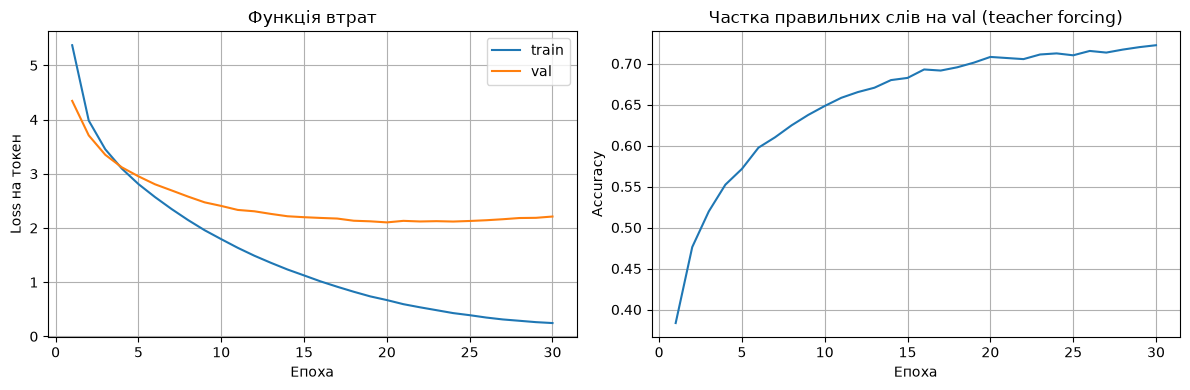

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), history['train_loss'], label='train')
plt.plot(range(1, EPOCHS + 1), history['val_loss'], label='val')
plt.xlabel('Епоха')
plt.ylabel('Loss на токен')
plt.title('Функція втрат')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), history['val_acc'])
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.title('Частка правильних слів на val (teacher forcing)')
plt.grid()

plt.tight_layout()
plt.show()

##### Аналіз learning curves. Чи є перенавчання?

Так. Тренувальна втрата падає рівно від 5.37 до 0.25, а валідаційна опускається лише до мінімуму 2.103 на 20-й епосі й далі повільно росте до 2.211. Криві перетинаються приблизно на 4-й епосі, після чого розрив між ними збільшується: на 30-й епосі він дорівнює 1.97. Модель дедалі краще запам'ятовує навчальні речення, але не стає краще на нових.

Accuracy на val при цьому продовжує зростати (0.708 на 20-й епосі, 0.722 на 30-й). Аccuracy враховує лише те, чи збіглося найімовірніше слово, а втрата штрафує за впевненість у помилкових словах. Мережа стає впевненішою, тому втрата зростає, хоча кількість правильних відповідей ще трохи збільшується.

Оптимально близько 20-ї епохи, і далі варто зупинятися (виконувати early stopping). Я навмисно залишив 30 епох, щоб перенавчання було видно.

Accuracy 72% тут це частка правильних слів за teacher forcing.

In [19]:
def encode_src(sentence):
    ids = encode(sentence, eng_stoi)[:MAX_LEN]
    return torch.tensor([ids], dtype=torch.long).to(device)


def decode_ids(ids):
    words = []
    for i in ids:
        if i in (PAD_IDX, BOS_IDX, EOS_IDX):
            continue
        words.append(nno_itos[i])
    return ' '.join(words)


@torch.no_grad()
def translate_ids(sentence):
    model.eval()
    src = encode_src(sentence)
    memory, src_mask = model.encode(src)

    tgt_ids = [BOS_IDX]
    for _ in range(MAX_LEN - 1):
        tgt = torch.tensor([tgt_ids], dtype=torch.long).to(device)
        logits = model.decode(tgt, memory, src_mask)
        next_id = logits[0, -1].argmax().item()
        tgt_ids.append(next_id)
        if next_id == EOS_IDX:
            break
    return tgt_ids


def translate(sentence):
    return decode_ids(translate_ids(sentence))

In [20]:
print('Приклади з validation (модель цих речень не бачила)')
print()
for eng, nno in val_pairs[:10]:
    print('EN:      ', eng)
    print('Еталон:  ', ' '.join(tokenize(nno)))
    print('Модель:  ', translate(eng))
    print()

Приклади з validation (модель цих речень не бачила)

EN:       You'd likely live longer if you ate healthier food.
Еталон:   du hadde sannsynlegvis levt lenger om du åt sunnare mat .
Модель:   du hadde nok om å selja ganske gode frå australia .

EN:       This is an ice cube.
Еталон:   dette er ein isbit .
Модель:   dette er ein mann .

EN:       I love Boston.
Еталон:   eg elskar boston .
Модель:   eg elskar boston .

EN:       There are many countries in Europe that I'd like to visit.
Еталон:   det er mange land i europa som eg har lyst til å vitja .
Модель:   det er mange ord i morgon eg hadde vore å ha sysken .

EN:       Are you happy to see me?
Еталон:   er du glad for å sjå meg ?
Модель:   er du tenkt å treffa meg ?

EN:       I had forgotten that.
Еталон:   det hadde eg gløymt av .
Модель:   eg hadde gløymt det .

EN:       Get your coat, Tom.
Еталон:   hent frakken din , tom .
Модель:   skaff deg frakken din .

EN:       Tom knows.
Еталон:   tom veit det .
Модель:   tom veit .

In [21]:
print('Приклади з train (модель ці речення бачила)')
print()
for eng, nno in train_pairs[:5]:
    print('EN:      ', eng)
    print('Еталон:  ', ' '.join(tokenize(nno)))
    print('Модель:  ', translate(eng))
    print()

Приклади з train (модель ці речення бачила)

EN:       Tom is reliable.
Еталон:   tom er påliteleg .
Модель:   tom er påliteleg .

EN:       Are you nuts?
Еталон:   er du gått frå vitet ?
Модель:   er du gått frå vitet ?

EN:       Bring me the flute.
Еталон:   hent meg fløyta .
Модель:   hent meg fløyta .

EN:       Tom and Mary wandered through the streets of the village.
Еталон:   tom og mary vandra gjennom gatene i landsbyen .
Модель:   tom og mary vandra gjennom gatene i landsbyen .

EN:       Tom has a grand piano in his living room.
Еталон:   tom har eit flygel i stova si .
Модель:   tom har eit flygel i stova si .



##### Приклади перекладу: нові та навчальні речення

__Val (модель цих речень не бачила).__ Результати можна розділити на три групи:

1. Точний або майже точний переклад: `I love Boston.` -> `eg elskar boston .`
2. Правильний за змістом, але інший за формою: `I had forgotten that.` -> `eg hadde gløymt det .` (еталон `det hadde eg gløymt av .`), `Tom knows.` -> `tom veit .` (пропущено `det`). Точний збіг такі переклади рахує помилкою.
3. Помилки в змісті: `ice cube` перекладено як `mann` (чоловік), `Everybody lies.` як `alle ser .`, довге речення про європейські країни перетворилося на неосмислений набір слів.

Структура речення та службові слова (`dette er ein`, `eg hadde`, `tom trudde`) вгадуються добре, а рідкісні іменники й дієслова підміняються частими словами. Модель вивчила «скелет» мови, але не словниковий запас, і це типовий наслідок малих даних.

__Train (модель ці речення бачила).__ Усі п'ять прикладів збігаються з еталоном слово в слово. Це запам'ятовування, а не розуміння.

In [22]:
examples = [
    'I am fine.',
    'Where is the book?',
    'Tom is my friend.',
    'We are at home.',
    'What time is it?',
    'She likes music.',
    'I do not know.',
    'Thank you very much.',
]

for s in examples:
    print('EN:', s)
    print('NN:', translate(s))
    print()

EN: I am fine.
NN: eg er veldig .

EN: Where is the book?
NN: kor er boka ?

EN: Tom is my friend.
NN: tom er saksofonlæraren min .

EN: We are at home.
NN: vi er heime .

EN: What time is it?
NN: kva er klokka det ?

EN: She likes music.
NN: ho likar musikk .

EN: I do not know.
NN: eg veit ikkje .

EN: Thank you very much.
NN: takk takk .



##### Власні речення

Прості й часті фрази перекладені правильно: `Where is the book?` -> `kor er boka ?`, `We are at home.` -> `vi er heime .`, `I do not know.` -> `eg veit ikkje .`, `She likes music.` -> `ho likar musikk .`

Частково правильні: `What time is it?` -> `kva er klokka det ?` (зайве `det`), `Thank you very much.` -> `takk takk .` (перекладено лише `takk`).

Помилки: `I am fine.` -> `eg er veldig .` (`veldig` означає «дуже»), а `Tom is my friend.` -> `tom er saksofonlæraren min .` (`friend` замінено на `saksofonlæraren`, тобто «викладач саксофона»). Імовірно, у Tatoeba багато речень про Tom і його заняття, тому ім'я тягне за собою типові для нього слова. Це приклад упередженості даних: модель вивчає не лише мову, а й розподіл слів у конкретному корпусі.

In [23]:
def exact_match(pairs_list):
    correct = 0
    for eng, nno in pairs_list:
        if translate(eng) == ' '.join(tokenize(nno)):
            correct = correct + 1
    return correct / len(pairs_list)


print('Точний збіг на train (перші 500):', exact_match(train_pairs[:500]))
print('Точний збіг на val:', exact_match(val_pairs))

Точний збіг на train (перші 500): 0.918
Точний збіг на val: 0.267260579064588


##### Точний збіг речень

Точний збіг на train 0.918, на val 0.267 (120 з 449 речень). Розрив у 65 пунктів це те саме перенавчання, але виміряне цілими реченнями, а не словами: на побачених реченнях модель майже безпомилкова, на нових переклад повністю збігається з еталоном приблизно в кожному четвертому випадку.

Головний результат: на 4 тисячах пар трансформер навчається граматиці, але не словнику.

\*P.S. Для train взято лише перші 500 речень, щоб швидше порахувати.

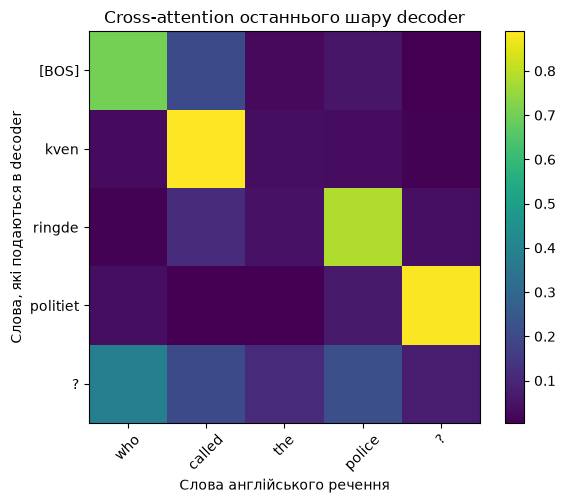

In [24]:
sentence = 'Who called the police?'
tgt_ids = translate_ids(sentence)

src = encode_src(sentence)
tgt_in = torch.tensor([tgt_ids[:-1]], dtype=torch.long).to(device)
model.eval()
with torch.no_grad():
    model(src, tgt_in)

attn = model.dec_layers[-1].cross_attn.last_attn[0].mean(dim=0).cpu().numpy()

src_words = tokenize(sentence)
tgt_words = [nno_itos[i] for i in tgt_ids[:-1]]
attn = attn[:len(tgt_words), :len(src_words)]

plt.figure(figsize=(6, 5))
plt.imshow(attn, cmap='viridis')
plt.xticks(range(len(src_words)), src_words, rotation=45)
plt.yticks(range(len(tgt_words)), tgt_words)
plt.xlabel('Слова англійського речення')
plt.ylabel('Слова, які подаються в decoder')
plt.title('Cross-attention останнього шару decoder')
plt.colorbar()
plt.tight_layout()
plt.show()

По горизонталі англійські слова, по вертикалі слова, які подаються в decoder (`tgt_in`). Колір це вага уваги (0 - 1): у кожному рядку ваги в сумі дають 1. Карта усереднена за чотирма головами останнього шару decoder.

Кожен рядок відповідає слову, __яке вже написано і після якого модель вгадує наступне__. Через зсув `tgt_in` / `tgt_out` діагональ виходить зсунутою на один рядок:

| Рядок (вхід decoder) | Яке слово вгадується | Куди дивиться decoder |
|---|---|---|
| `[BOS]` | `kven` | `who` (≈0.7) |
| `kven` | `ringde` | `called` (≈0.9) |
| `ringde` | `politiet` | `police` (≈0.8) |
| `politiet` | `?` | `?` (≈0.9) |
| `?` | кінець речення | увага розподілена по всіх словах, виразної немає |

Тобто перед тим як написати слово, decoder дивиться на англійське слово, яке саме йому відповідає. Вирівнювання слів (`who` - `kven`, `called` - `ringde`, `police` - `politiet`) модель знайшла сама. Це показує, що вона вивчила зв'язок між мовами, а не лише запам'ятала фрази.

У цього речення порядок слів в обох мовах однаковий, тому карта близька до діагоналі. Для мов з іншим порядком слів вона була б розкидана.

##### Висновки частини 1

1. Власний Transformer encoder-decoder (1 974 744 параметрів, 3 шари, 4 голови) навчився перекладати прості речення: accuracy по словах на val 0.722, точний збіг на train 0.918, на val 0.267.
2. Learning curves показують чітке перенавчання: мінімум val loss 2.103 на 20-й епосі, далі втрата росте, а train loss падає до 0.25. Для кращої якості треба більше даних або ранній зупин; dropout 0.1 тут замалий.
3. Помилки закономірні: модель добре відтворює структуру речення й часті слова, але підміняє рідкісні (`ice cube` -> `mann`) і копіює упередженості корпусу (`friend` -> `saksofonlæraren`).
4. Карта cross-attention підтвердила, що модель сама вивчила вирівнювання слів між двома мовами.
5. Головна причина слабшого перекладу не в архітектурі, а в обсязі даних: чотири тисячі речень замало, щоб вивчити мову.

##### Частина 2а. Готові моделі Hugging Face з підтримкою української мови (pipeline)

`pipeline` об'єднує токенізатор, модель і форматування відповіді в один виклик. Для кожного завдання взято окрему модель, яка підтримує українську:

| Завдання | Модель | Тип архітектури |
|---|---|---|
| zero-shot classification | `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | лише encoder, донавчена на NLI багатьма мовами |
| summarization | `csebuetnlp/mT5_multilingual_XLSum` | encoder-decoder, донавчена на коротких змістах новин багатьма мовами |
| translation | `Helsinki-NLP/opus-mt-uk-en` | encoder-decoder (Marian), навчена на парах речень uk - en |

In [25]:
from transformers import pipeline

zero_shot = pipeline(
    'zero-shot-classification',
    model='MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7',
    device=device,
)

text = 'Вчора збірна України з футболу виграла важливий матч у відбірковому турнірі.'
labels = ['спорт', 'політика', 'економіка', 'наука']

result = zero_shot(text, candidate_labels=labels, hypothesis_template='Це текст про {}.')

print(text)
print()
for label, score in zip(result['labels'], result['scores']):
    print(label, round(score, 3))

/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Device set to use cpu


Вчора збірна України з футболу виграла важливий матч у відбірковому турнірі.

спорт 0.997
наука 0.001
політика 0.001
економіка 0.0


##### Zero-shot classification: результат

Модель віднесла речення про футбол до теми «спорт» з імовірністю 0.997, решта тем отримала 0.001 або менше. Класифікатор не бачив жодного прикладу з нашими мітками.

Як це працює: zero-shot перетворює класифікацію на задачу логічного виведення (NLI). Для кожної мітки складається гіпотеза за шаблоном `Це текст про {}.`, а модель оцінює, чи випливає вона з тексту. Мітка з найвищою оцінкою перемагає.

Приклад очевидний, і майже 1.0 для переможця тут нормально. Якби в списку не було правильної теми, модель усе одно вибрала б одну з наявних. Формулювання шаблону впливає на результат, тому його варто підбирати.

In [26]:
summarizer = pipeline(
    'summarization',
    model='csebuetnlp/mT5_multilingual_XLSum',
    device=device,
)

long_text = (
    'У Львові відкрили оновлену міську бібліотеку. Реконструкція тривала два роки, '
    'і за цей час будівля отримала нові читальні зали, безкоштовний доступ до інтернету '
    'та окремий простір для дитячих занять. Фонд бібліотеки поповнили понад десять тисяч '
    'нових книжок, серед яких підручники, художня література та видання іноземними мовами. '
    'Також запрацювала електронна платформа, яка дозволяє замовити книжку онлайн і забрати '
    'її в найближчому відділенні. За словами директорки закладу, за перший тиждень роботи '
    'бібліотеку відвідали кілька сотень людей, а найбільший інтерес викликали курси '
    'програмування для школярів.'
)

summary = summarizer(long_text, max_length=60, min_length=10, no_repeat_ngram_size=2, num_beams=4)

print('Оригінал:', long_text)
print()
print('Короткий зміст:', summary[0]['summary_text'])

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.

Оригінал: У Львові відкрили оновлену міську бібліотеку. Реконструкція тривала два роки, і за цей час будівля отримала нові читальні зали, безкоштовний доступ до інтернету та окремий простір для дитячих занять. Фонд бібліотеки поповнили понад десять тисяч нових книжок, серед яких підручники, художня література та видання іноземними мовами. Також запрацювала електронна платформа, яка дозволяє замовити книжку онлайн і забрати її в найближчому відділенні. За словами директорки закладу, за перший тиждень роботи бібліотеку відвідали кілька сотень людей, а найбільший інтерес викликали курси програмування для школярів.

Короткий зміст: У Львові відкрили оновлену міську бібліотеку.


##### Summarization: результат

Модель стиснула п'ять речень до одного: «У Львові відкрили оновлену міську бібліотеку». Це відповідає головному факту тексту, але всі подробиці (реконструкція, нові книжки, електронна платформа, курси програмування) втрачено.

Така лаконічність закладена в моделі: `mT5_multilingual_XLSum` навчена на новинах BBC, де короткий зміст це одне речення, тому й тут вона видає одне речення. Параметри генерації: `num_beams=4` (beam search тримає чотири кращі варіанти фрази замість найімовірнішого слова на кожному кроці), `no_repeat_ngram_size=2` (забороняє повтор пар слів), `max_length=60`, `min_length=10`.

Це абстрактне стиснення: модель пише власний текст, а не вирізає речення з оригіналу. Тому такі моделі можуть додати неточність, і результат варто перевіряти.

In [27]:
translator = pipeline(
    'translation',
    model='Helsinki-NLP/opus-mt-uk-en',
    device=device,
)

uk_text = 'Інтелектуальний аналіз даних допомагає знаходити закономірності у великих масивах інформації.'
translation = translator(uk_text)

print('UK:', uk_text)
print('EN:', translation[0]['translation_text'])

/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cpu


UK: Інтелектуальний аналіз даних допомагає знаходити закономірності у великих масивах інформації.
EN: Intellectual data analysis helps us to find patterns in large arrays of information.


##### Translation: результат і висновки частини 2а

Переклад змістовно правильний: «Intellectual data analysis helps us to find patterns in large arrays of information». Видно й слабкі місця: «helps us» додано, у вихідному реченні цього немає, а «intellectual data analysis» і «arrays» це буквальні кальки (природніше було б «data mining» чи «large datasets»).

Архітектура цієї моделі (Marian) та сама, що в частині 1, але через різницю в даних (в їх кількості на яких вона навчена) я б сформулював такий головний висновок про трансформери: якість визначається не лише архітектурою, а й також обсягом даних.

##### Частина 2б. Fine-tuning DistilBERT для класифікації тегів фільмів за жанром

##### Постановка задачі

Та сама задача, що в лабораторній роботі 2: за тегами, які користувачі поставили фільму, визначити жанр (Comedy, Drama, Horror). Там вона розв'язувалася через TF-IDF та Naive Bayes. Тепер береться претренована модель DistilBERT і повністю донавчається (full fine-tuning) на цих даних.

Дані, розбиття на train/test (`test_size=0.3`, `random_state=10`, `stratify`) і метрики відтворено з лабораторної роботи 2, щоб порівняння було коректним: ті самі 317 тестових документів, ті самі accuracy та macro-F1.

In [28]:
import re
import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
)

In [29]:
tags = pd.read_csv('../lab2/ml-latest-small/tags.csv')
movies = pd.read_csv('../lab2/ml-latest-small/movies.csv')

docs = tags.groupby('movieId')['tag'].agg(' '.join).reset_index()
data = movies.merge(docs, on='movieId')
print(data.shape)
print(data[['title', 'genres', 'tag']].head())

(1572, 4)
                                title  \
0                    Toy Story (1995)   
1                      Jumanji (1995)   
2             Grumpier Old Men (1995)   
3  Father of the Bride Part II (1995)   
4                      Sabrina (1995)   

                                        genres  \
0  Adventure|Animation|Children|Comedy|Fantasy   
1                   Adventure|Children|Fantasy   
2                               Comedy|Romance   
3                                       Comedy   
4                               Comedy|Romance   

                                            tag  
0                               pixar pixar fun  
1  fantasy magic board game Robin Williams game  
2                                     moldy old  
3                              pregnancy remake  
4                                        remake  


In [30]:
chosen = ['Comedy', 'Drama', 'Horror']


def get_label(genres):
    genre_list = genres.split('|')
    found = []
    for g in chosen:
        if g in genre_list:
            found.append(g)
    if len(found) == 1:
        return found[0]
    return None


data['label'] = data['genres'].apply(get_label)
data = data.dropna(subset=['label'])
print(data['label'].value_counts())

label
Drama     682
Comedy    332
Horror     52
Name: count, dtype: int64


##### Вибір класів

Фільм зазвичай має кілька жанрів, а потрібна одна мітка, тому залишено лише фільми, які мають рівно один із трьох обраних жанрів: Drama 682, Comedy 332, Horror 52, разом 1 066.

Класи сильно незбалансовані. Drama становить близько 64%, тобто тривіальна модель «завжди Drama» мала б accuracy близько 0.64. З цим числом і потрібно порівнювати результати, а поряд з accuracy дивитися на macro-F1, який однаково враховує всі три класи.

In [31]:
def clean_text(text):
    text = text.lower()
    text = re.sub('[^a-z ]', ' ', text)
    words = text.split()
    result = []
    for word in words:
        if word not in ENGLISH_STOP_WORDS and len(word) > 2:
            result.append(word)
    return ' '.join(result)


data['clean_text'] = data['tag'].apply(clean_text)
data = data[data['clean_text'] != '']
print(data.shape)
print(data[['tag', 'clean_text']].head())

(1056, 6)
                  tag          clean_text
0     pixar pixar fun     pixar pixar fun
2           moldy old           moldy old
3    pregnancy remake    pregnancy remake
4              remake              remake
6  politics president  politics president


##### Очищення тексту

Очищення те саме, що в лабораторній 2: нижній регістр, залишаються лише латинські літери, видаляються стоп-слова.

Для BERT очищення не обов'язкове, бо він сам вчиться ігнорувати службові слова. Воно залишено, щоб обидві моделі навчалися на тих самих текстах і різниця в результатах була пов'язана саме з моделлю.

In [32]:
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    data['clean_text'], data['label'], test_size=0.3, random_state=10, stratify=data['label'])

print('Train:', len(X_train_text))
print('Test:', len(X_test_text))
print(y_test_text.value_counts())

Train: 739
Test: 317
label
Drama     203
Comedy     99
Horror     15
Name: count, dtype: int64


##### Розбиття на train і test

Розбиття 70 / 30 з тими самими параметрами, що в лабораторній 2: Train 739, Test 317. У тесті Drama 203, Comedy 99, Horror 15. `stratify` зберігає пропорції класів.

Horror у тесті лише 15 документів, тому один правильно чи неправильно визначений фільм змінює recall цього класу на 6.7 пункта. Метрики для Horror шумні, і висновки про цей клас треба робити обережно.

In [33]:
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

nb_model = MultinomialNB(alpha=0.1)
nb_model.fit(X_train_tfidf, y_train_text)
y_pred_nb = nb_model.predict(X_test_tfidf)

print(classification_report(y_test_text, y_pred_nb))
print(confusion_matrix(y_test_text, y_pred_nb))

              precision    recall  f1-score   support

      Comedy       0.78      0.51      0.61        99
       Drama       0.77      0.93      0.84       203
      Horror       0.75      0.40      0.52        15

    accuracy                           0.77       317
   macro avg       0.77      0.61      0.66       317
weighted avg       0.77      0.77      0.76       317

[[ 50  48   1]
 [ 13 189   1]
 [  1   8   6]]


##### Базова модель: TF-IDF + Naive Bayes

Це результат лабораторної роботи 2, відтворений тут: accuracy 0.77, macro-F1 0.66.

Звіт показує, що модель найкраще впізнає Drama (recall 0.93) і гірше Comedy (0.51) та Horror (0.40). У матриці помилок 48 комедій названо драмами, а 9 фільмів жахів із 15 класифіковано неправильно.

In [34]:
label_names = ['Comedy', 'Drama', 'Horror']
label_to_id = {'Comedy': 0, 'Drama': 1, 'Horror': 2}

y_train_ids = [label_to_id[label] for label in y_train_text]
y_test_ids = [label_to_id[label] for label in y_test_text]

model_name = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)


def tokenize_batch(batch):
    return tokenizer(batch['text'], truncation=True, max_length=64)


train_dataset = Dataset.from_dict({'text': X_train_text.tolist(), 'label': y_train_ids})
test_dataset = Dataset.from_dict({'text': X_test_text.tolist(), 'label': y_test_ids})

train_dataset = train_dataset.map(tokenize_batch, batched=True)
test_dataset = test_dataset.map(tokenize_batch, batched=True)

print(train_dataset)
print(tokenizer.tokenize(X_train_text.iloc[0]))

Map: 100%|██████████| 317/317 [00:00<00:00, 49080.63 examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 739
})
['adult', 'humor', 'controversial', 'crude', 'humor', 'free', 'speech', 'parody', 'satire', 'south', 'park', 'trey', 'parker']


##### Підготовка даних для DistilBERT

`AutoTokenizer` розбиває текст на токени WordPiece і замінює їх номерами зі словника моделі (`input_ids`), а `attention_mask` позначає реальні токени. `max_length=64` обмежує довжину: наші тексти значно коротші.

Приклад розбиття (`adult`, `humor`, `controversial`, `crude`, ... `trey`, `parker`) показує, що майже всі слова є у словнику цілком і не дробляться на частини. Доповнення до однакової довжини робить `DataCollatorWithPadding` для кожного батча окремо, тому на коротких текстах не витрачається зайвий час.

Токенізатор має бути саме той, що в моделі: словник претренованої моделі не можна замінити своїм.

In [35]:
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1_macro': f1_score(labels, preds, average='macro'),
    }


training_args = TrainingArguments(
    output_dir='distilbert-movielens',
    eval_strategy='epoch',
    save_strategy='no',
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    report_to='none',
    seed=10,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


##### Модель і гіперпараметри

`AutoModelForSequenceClassification` бере претреновану модель `distilbert-base-uncased` (приблизно 66 млн параметрів) і додає зверху новий класифікаційний шар із трьома виходами. 

| Гіперпараметр | Значення | Пояснення |
|---|---|---|
| `learning_rate` | 5e-5 | дуже мала швидкість, щоб не зруйнувати знання претренованої моделі |
| `per_device_train_batch_size` | 16 | 47 кроків на епоху, 235 кроків за 5 епох |
| `num_train_epochs` | 5 | для малого датасету достатньо, далі починається перенавчання |
| `weight_decay` | 0.01 | регуляризація |
| `seed` | 10 | відтворюваність |

Це повне донавчання (full fine-tuning): оновлюються всі ваги моделі.

`eval_dataset` це тестова вибірка, тому після кожної епохи друкуються метрики на тесті. Це лише спостереження за навчанням: епоху за ними не вибирали, фінальною є модель після 5-ї епохи.

In [36]:
trainer.train()

/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.675836,0.738170,0.458204
2,No log,0.629137,0.750789,0.492674
3,No log,0.533714,0.788644,0.675744
4,No log,0.584108,0.794953,0.714221
5,No log,0.607870,0.782334,0.694279


/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, dev

TrainOutput(global_step=235, training_loss=0.5050431271816822, metrics={'train_runtime': 30.7852, 'train_samples_per_second': 120.025, 'train_steps_per_second': 7.634, 'total_flos': 18683410904424.0, 'train_loss': 0.5050431271816822, 'epoch': 5.0})

##### Хід навчання

| Епоха | Val loss | Accuracy | F1 macro |
|---|---|---|---|
| 1 | 0.676 | 0.738 | 0.458 |
| 2 | 0.629 | 0.751 | 0.493 |
| 3 | 0.534 | 0.789 | 0.676 |
| 4 | 0.584 | 0.795 | 0.714 |
| 5 | 0.608 | 0.782 | 0.694 |

Після першої епохи accuracy 0.738 вже вища за тривіальні 0.64, але macro-F1 лише 0.458: модель майже все називає Drama. Стрибок macro-F1 з 0.49 до 0.68 на 3-й епосі означає, що модель почала розрізняти Comedy та Horror.

Мінімум втрати припав на 3-ю епоху (0.534), а далі вона зростає до 0.608: це початок перенавчання, хоч і слабкого, бо accuracy та F1 змінилися мало. Найвищі accuracy та macro-F1 були на 4-й епосі. Середня втрата на train за все навчання 0.505.

In [37]:
predictions = trainer.predict(test_dataset)
y_pred_ids = np.argmax(predictions.predictions, axis=1)
y_pred_bert = [label_names[i] for i in y_pred_ids]

print(classification_report(y_test_text, y_pred_bert))
print(label_names)
print(confusion_matrix(y_test_text, y_pred_bert, labels=label_names))

/Users/f4llk1ng/Documents/Personal/uni/maga/5_1/ІАД/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

      Comedy       0.78      0.57      0.65        99
       Drama       0.80      0.90      0.85       203
      Horror       0.56      0.60      0.58        15

    accuracy                           0.78       317
   macro avg       0.71      0.69      0.69       317
weighted avg       0.78      0.78      0.77       317

['Comedy', 'Drama', 'Horror']
[[ 56  40   3]
 [ 16 183   4]
 [  0   6   9]]


##### Якість DistilBERT на тесті

| Клас | Precision | Recall | F1 |
|---|---|---|---|
| Comedy | 0.78 | 0.57 | 0.65 |
| Drama | 0.80 | 0.90 | 0.85 |
| Horror | 0.56 | 0.60 | 0.58 |

Правильно класифіковано 248 із 317 документів (0.782). У матриці помилок по діагоналі 56, 183 і 9.

Порівняно з Naive Bayes модель знаходить більше комедій (56 із 99 замість 50) та фільмів жахів (9 із 15 замість 6), але трохи гірше впізнає Drama (183 із 203 замість 189). Для Horror це має ціну: precision впала з 0.75 до 0.56, бо 7 інших фільмів помилково названо жахами (у Naive Bayes їх було 2). Тобто модель стала «сміливішою» в рідкісних класах.

In [38]:
f1_nb = f1_score(y_test_text, y_pred_nb, average=None, labels=label_names)
f1_bert = f1_score(y_test_text, y_pred_bert, average=None, labels=label_names)

results = pd.DataFrame({
    'Модель': ['TF-IDF + Naive Bayes (лаб. 2)', 'DistilBERT fine-tuning'],
    'Accuracy': [accuracy_score(y_test_text, y_pred_nb), accuracy_score(y_test_text, y_pred_bert)],
    'F1 macro': [f1_score(y_test_text, y_pred_nb, average='macro'), f1_score(y_test_text, y_pred_bert, average='macro')],
    'F1 Comedy': [f1_nb[0], f1_bert[0]],
    'F1 Drama': [f1_nb[1], f1_bert[1]],
    'F1 Horror': [f1_nb[2], f1_bert[2]],
})
print(results.round(3).to_string())

                          Модель  Accuracy  F1 macro  F1 Comedy  F1 Drama  F1 Horror
0  TF-IDF + Naive Bayes (лаб. 2)     0.773     0.660      0.613     0.844      0.522
1         DistilBERT fine-tuning     0.782     0.694      0.655     0.847      0.581


##### Порівняння з лабораторною роботою 2 та висновок

| Модель | Accuracy | F1 macro | F1 Comedy | F1 Drama | F1 Horror |
|---|---|---|---|---|---|
| TF-IDF + Naive Bayes (лаб. 2) | 0.773 | 0.660 | 0.613 | 0.844 | 0.522 |
| DistilBERT fine-tuning | 0.782 | 0.694 | 0.655 | 0.847 | 0.581 |

DistilBERT формально кращий за всіма метриками, але різниця мала. Accuracy вища на 0.9 пункта, це 3 документи з 317 (248 проти 245).

Це один запуск із одним `seed`, тому говорити про суттєву перевагу не можна.

__Чому приріст такий малий.__

1. Текст це 1-3 теги без граматики, тому основна перевага трансформера (контекст і порядок слів) тут майже не працює.
2. TF-IDF з Naive Bayes уже добре ловить ключові слова («zombie», «gore», «funny»).
3. Даних мало: 739 навчальних документів, 52 з них Horror.
4. Фільм може мати кілька жанрів, і теги неоднозначні, тому частину помилок не усуне жодна модель.

__Висновки частини 2б.__

1. Fine-tuning DistilBERT дав невелике покращення відносно Naive Bayes (macro-F1 0.694 проти 0.660) при коректному порівнянні на тих самих даних і метриках.
2. Приріст сумірний із розкидом, який можна очікувати на 317 документах, тому це радше «не гірше», ніж «краще».
3. Ціна покращення: 66 млн параметрів і близько 30 секунд навчання проти практично миттєвого Naive Bayes.

##### Частина 3а. Text-to-Image: генерація зображення за текстовим описом (Diffusers)

##### Постановка задачі

Згенерувати зображення за текстовим описом (prompt) за допомогою Stable Diffusion через бібліотеку `diffusers`, показати запит і результат.

Модель Stable Diffusion це латентна дифузійна модель. Вона починає з випадкового шуму й крок за кроком прибирає його, а текст підказує, що саме має проявитися. Складається з трьох частин: текстового encoder (CLIP) перетворює запит на вектори, U-Net прибирає шум у стисненому («латентному») просторі, а VAE-decoder розгортає результат у картинку 512x512.

In [39]:
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

model_id = 'CompVis/stable-diffusion-v1-4'

if device.type == 'cuda':
    pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch.float16)
else:
    pipe = StableDiffusionPipeline.from_pretrained(model_id)

pipe = pipe.to(device)

Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00, 18.14it/s]


In [40]:
prompt = (
    'a cozy wooden cabin in a snowy pine forest at sunset, warm light in the windows, '
    'smoke from the chimney, highly detailed digital painting'
)

generator = torch.Generator(device=device).manual_seed(10)
image = pipe(prompt, num_inference_steps=30, guidance_scale=7.5, generator=generator).images[0]

print('Запит:', prompt)
print('Розмір зображення:', image.size)

100%|██████████| 30/30 [01:01<00:00,  2.05s/it]


Запит: a cozy wooden cabin in a snowy pine forest at sunset, warm light in the windows, smoke from the chimney, highly detailed digital painting
Розмір зображення: (512, 512)


##### Параметри генерації

`num_inference_steps=30` це кількість кроків очищення від шуму: більше кроків дає чистішу картинку, але генерація довша (тут приблизно 61 секунда, 2 секунди на крок).

`guidance_scale=7.5` визначає, наскільки суворо слідувати тексту. Мале значення дає більшу свободу й відхід від опису, велике дає буквальність і перенасичені кольори; 7.5 це стандартний баланс.

`generator` із `manual_seed(10)` фіксує початковий шум: з тим самим запитом і `seed` вийде та сама картинка, з іншим `seed` вийде інша.

Запит складено з предмета («cozy wooden cabin»), обстановки («snowy pine forest at sunset»), деталей («warm light in the windows, smoke from the chimney») та стилю («highly detailed digital painting»). Детальний запит зазвичай дає передбачуваніший результат.

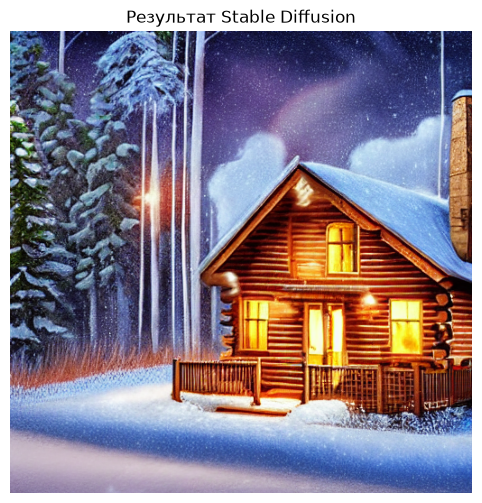

In [41]:
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis('off')
plt.title('Результат Stable Diffusion')
plt.show()

##### Результат та інтерпретація

Модель правильно передала основні елементи запиту: дерев'яну хатину, сніг, ялини та теплі жовті вікна. Картинка виглядає як цифровий малюнок, як і було запрошено, і в ній є деталі: колоди зрубу, перила ґанку, сніжинки в повітрі.

Є й розбіжності з описом. Небо схоже скоріше на сутінки з фіолетовими відтінками, ніж на захід сонця, а дим із димаря добре не видно (труба обрізана по краю кадру). Модель не гарантує точного виконання кожної деталі запиту.

Висновок: дифузійна модель дозволяє отримати доволі якісне зображення за словесним описом.

##### Частина 3б. DINOv2: вектори ознак зображень, L2-нормування, попарні відстані

##### Постановка задачі

Вибрати 10 різних зображень, візуалізувати їх, отримати вектори ознак моделлю DINOv2, виконати L2-нормування, порахувати всі попарні евклідові відстані та знайти найближчу й найвіддаленішу пари. Потім коротко прокоментувати, чи збігається це з візуальним сприйняттям.

DINOv2 це Vision Transformer, навчений без міток (self-supervised): картинка розрізається на квадрати 14x14 пікселів, і кожен квадрат стає «словом» для трансформера. Окремий токен `[CLS]` збирає інформацію про всю картинку, і саме його вектор (384 числа для `dinov2-small`) використовується як опис зображення. Модель тут не донавчається, а лише дає ознаки (feature extraction).

In [42]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from torchvision.datasets import OxfordIIITPet
from transformers import AutoImageProcessor, AutoModel

random.seed(10)

In [43]:
dataset = OxfordIIITPet(root='./data', split='test', target_types='category', download=True)

print('Зображень у тестовій частині:', len(dataset))
print('Порід:', len(dataset.classes))
print(dataset.classes)

100%|██████████| 792M/792M [00:20<00:00, 38.3MB/s] 
100%|██████████| 19.2M/19.2M [00:00<00:00, 22.1MB/s]


Зображень у тестовій частині: 3669
Порід: 37
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


##### Датасет

Датасети лабораторної 2 зображень не містять, тому взято Oxford-IIIT Pet: 37 порід котів і собак. Використано тестову частину, 3 669 фотографій. Кожна порода представлена приблизно 100 фотографіями, а фото відрізняються позою, освітленням, тлом і розміром.

Індекси: [73, 4, 552, 559, 1058, 986, 812, 845, 2943, 2916]
Розміри оригіналів: [(500, 375), (300, 279), (500, 375), (500, 333), (368, 500), (300, 225), (500, 333), (333, 500), (500, 404), (500, 334)]


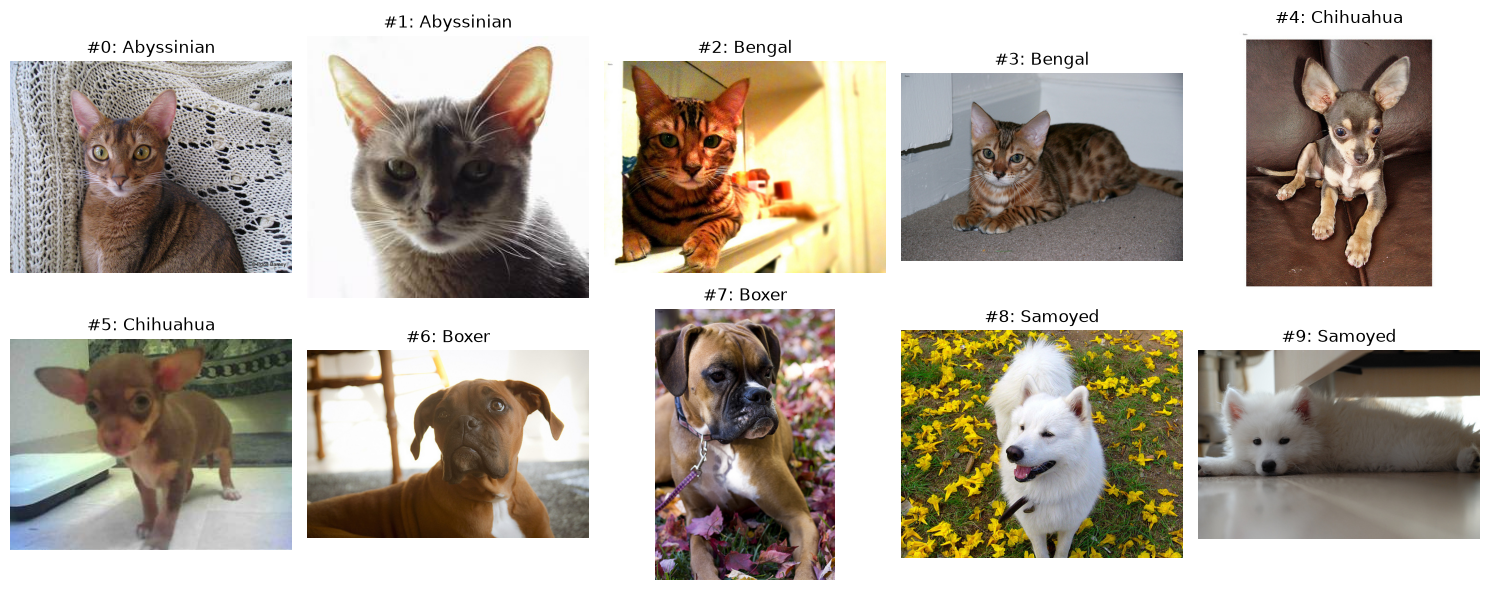

In [44]:
chosen_breeds = ['Abyssinian', 'Bengal', 'Chihuahua', 'Boxer', 'Samoyed']
labels_all = dataset._labels

selected_indices = []
for breed in chosen_breeds:
    breed_id = dataset.class_to_idx[breed]
    breed_indices = [i for i in range(len(labels_all)) if labels_all[i] == breed_id]
    selected_indices = selected_indices + random.sample(breed_indices, 2)

images = []
names = []
for idx in selected_indices:
    image, label = dataset[idx]
    images.append(image)
    names.append(dataset.classes[label])

print('Індекси:', selected_indices)
print('Розміри оригіналів:', [img.size for img in images])

plt.figure(figsize=(15, 6))
for i in range(len(images)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i])
    plt.title(f'#{i}: {names[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

##### Вибрані зображення

Взято п'ять порід і по два випадкові фото кожної: Abyssinian, Bengal (коти), Chihuahua, Boxer, Samoyed (собаки). Так можна передбачити результат ще до розрахунку: фото однієї породи мають бути ближчими одне до одного, ніж фото різних порід, а коти мають відрізнятися від собак.

Фото відрізняються за розміром (оригінали 300x225, 500x375 тощо), тому `processor` приводить їх до однакового `224x224`, зі зміною масштабу та обрізанням.

In [45]:
model_name = 'facebook/dinov2-small'
processor = AutoImageProcessor.from_pretrained(model_name)
dino = AutoModel.from_pretrained(model_name).to(device)
dino.eval()

inputs = processor(images=images, return_tensors='pt').to(device)
with torch.no_grad():
    outputs = dino(**inputs)

features = outputs.last_hidden_state[:, 0, :].cpu()

print('Форма входу в модель:', inputs['pixel_values'].shape)
print('Форма матриці ознак:', features.shape)
print('Норми до нормування:', features.norm(dim=1).numpy().round(2))

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Форма входу в модель: torch.Size([10, 3, 224, 224])
Форма матриці ознак: torch.Size([10, 384])
Норми до нормування: [51.32 50.94 50.55 50.07 49.69 49.07 49.38 50.46 48.34 49.31]


##### Вектори ознак

Форма входу `[10, 3, 224, 224]` це 10 зображень, 3 канали кольору, 224x224 пікселів. Форма ознак `[10, 384]` означає, що кожне фото тепер описується 384 числами, тобто вектором `[CLS]` з останнього шару.

Довжини (норми) векторів до нормування становлять близько 48-51, тобто відрізняються. Якби порівнювати такі вектори напряму, на відстань впливала б і довжина вектора, а не лише його напрям. Нормування вирівнює довжини, і відстань відображає лише відмінність за змістом.

Норми після нормування: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Форма матриці відстаней: (10, 10)


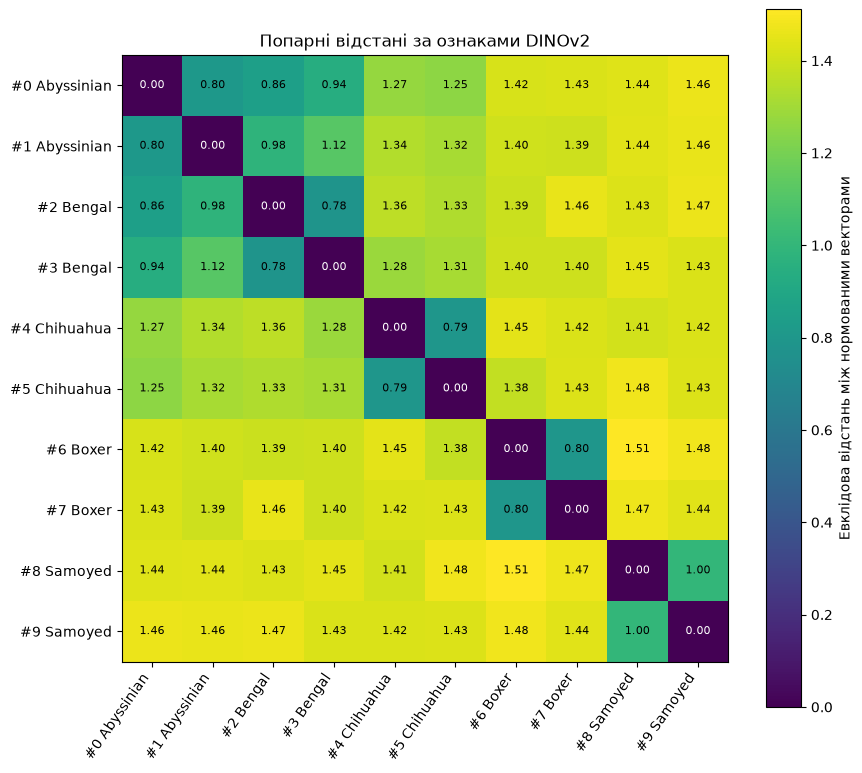

In [46]:
features_norm = F.normalize(features, p=2, dim=1)
print('Норми після нормування:', features_norm.norm(dim=1).numpy().round(4))

distances = torch.cdist(features_norm, features_norm, p=2).numpy()
print('Форма матриці відстаней:', distances.shape)

tick_labels = [f'#{i} {names[i]}' for i in range(len(names))]

plt.figure(figsize=(9, 8))
plt.imshow(distances, cmap='viridis')
plt.xticks(range(len(names)), tick_labels, rotation=55, ha='right')
plt.yticks(range(len(names)), tick_labels)
for i in range(len(names)):
    for j in range(len(names)):
        color = 'white' if distances[i, j] < distances.max() / 2 else 'black'
        plt.text(j, i, f'{distances[i, j]:.2f}', ha='center', va='center', color=color, fontsize=8)
plt.colorbar(label='Евклідова відстань між нормованими векторами')
plt.title('Попарні відстані за ознаками DINOv2')
plt.tight_layout()
plt.show()

##### L2-нормування та матриця відстаней

Матриця симетрична 10x10: на діагоналі нулі (фото порівнюється з собою), а клітинка `(i, j)` це відстань між фото `i` та `j`. Темні клітинки означають схожі фото, світлі різні.

Можемо побачити такі закономірності:

1. Уздовж діагоналі є темні квадрати 2x2: фото однієї породи близькі (0.78-0.80). Виняток Samoyed, де відстань 1.00, бо на цих фото різні поза, тло та ракурс.
2. Коти утворюють темніший блок у верхньому лівому куті: відстані між усіма чотирма котами 0.78-1.12, а між котами та собаками 1.25-1.47.
3. Серед собак такого блоку немає: Chihuahua, Boxer і Samoyed між собою на відстані 1.38-1.51, тобто так само далеко, як коти від собак. Це дуже різні тварини за розміром, формою та кольором. Chihuahua навіть ближча до котів (1.25-1.36), ніж до інших порід собак (1.38-1.48), імовірно, через маленький розмір і великі вуха.

In [47]:
pair_list = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        pair_list.append((distances[i, j], i, j))
pair_list.sort()

pairs_table = pd.DataFrame({
    'Фото 1': [p[1] for p in pair_list],
    'Фото 2': [p[2] for p in pair_list],
    'Порода 1': [names[p[1]] for p in pair_list],
    'Порода 2': [names[p[2]] for p in pair_list],
    'Відстань': [p[0] for p in pair_list],
})

print('Кількість різних пар:', len(pair_list))
print('Найближчі п\'ять пар')
print(pairs_table.head(5).round(4))
print()
print('Найвіддаленіші п\'ять пар')
print(pairs_table.tail(5).round(4))

nearest_pair = pair_list[0]
farthest_pair = pair_list[-1]
print()
print('Найближча пара:', nearest_pair[1], nearest_pair[2], round(float(nearest_pair[0]), 4))
print('Найвіддаленіша пара:', farthest_pair[1], farthest_pair[2], round(float(farthest_pair[0]), 4))

Кількість різних пар: 45
Найближчі п'ять пар
   Фото 1  Фото 2    Порода 1    Порода 2  Відстань
0       2       3      Bengal      Bengal    0.7832
1       4       5   Chihuahua   Chihuahua    0.7926
2       6       7       Boxer       Boxer    0.7964
3       0       1  Abyssinian  Abyssinian    0.8037
4       0       2  Abyssinian      Bengal    0.8557

Найвіддаленіші п'ять пар
    Фото 1  Фото 2   Порода 1 Порода 2  Відстань
40       2       9     Bengal  Samoyed    1.4688
41       7       8      Boxer  Samoyed    1.4722
42       5       8  Chihuahua  Samoyed    1.4770
43       6       9      Boxer  Samoyed    1.4785
44       6       8      Boxer  Samoyed    1.5109

Найближча пара: 2 3 0.7832
Найвіддаленіша пара: 6 8 1.5109


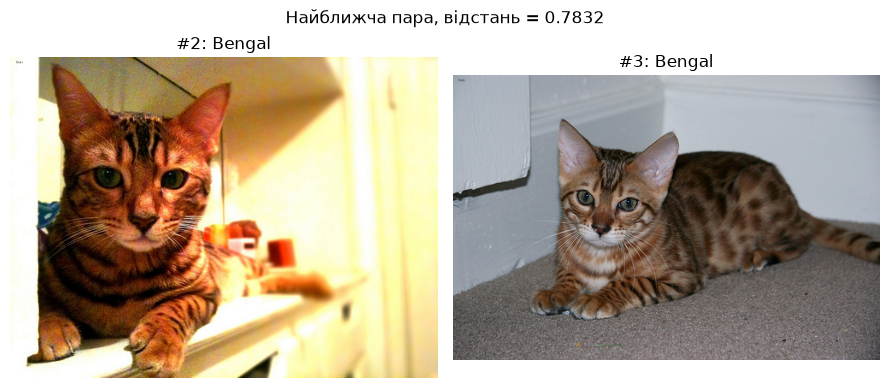

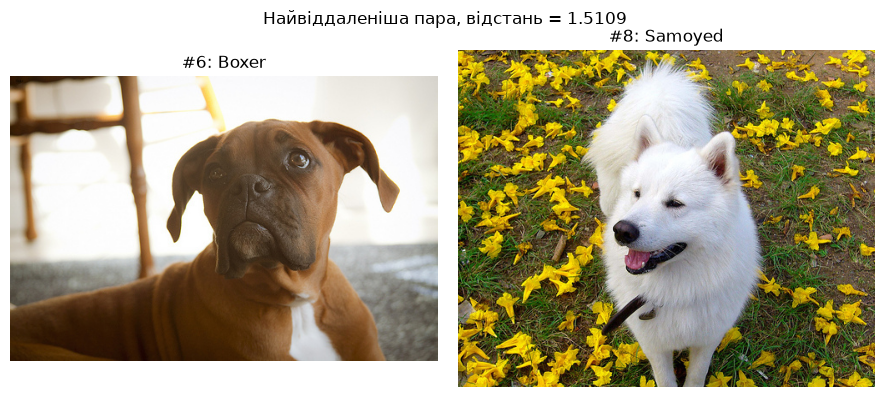

In [48]:
def show_pair(pair, title):
    dist, i, j = pair
    plt.figure(figsize=(9, 4))
    for k, idx in enumerate([i, j]):
        plt.subplot(1, 2, k + 1)
        plt.imshow(images[idx])
        plt.title(f'#{idx}: {names[idx]}')
        plt.axis('off')
    plt.suptitle(f'{title}, відстань = {dist:.4f}')
    plt.tight_layout()
    plt.show()


show_pair(nearest_pair, 'Найближча пара')
show_pair(farthest_pair, 'Найвіддаленіша пара')

##### Візуальне сприйняття vs Результат

__Найближча пара (#2 та #3, обидва Bengal, 0.7832).__ Збігається: це кішки однієї породи з однаковим плямисто-смугастим помаранчево-коричневим забарвленням, обидві дивляться в камеру. Цікаво, що фото #2 має сильний теплий жовтий відтінок через освітлення, а #3 нейтральніше, але на відстань це майже не вплинуло. Тобто DINOv2 порівнює зміст (порода, поза, текстура шерсті), а не загальний колір чи яскравість картинки.

__Найвіддаленіша пара (#6 Boxer та #8 Samoyed, 1.5109).__ Збігається: коричнева короткошерста собака в приміщенні та біла пухнаста собака на траві з жовтими квітами контрастують за кольором, шерстю й тлом.

__Де розходиться.__ Дві собаки порід Boxer і Samoyed далекі приблизно так само, як кішка й собака, хоча «людською» логікою обидві собаки мають бути ближчими одна до одної, ніж до кішки. Тобто модель вирізняє не лише вид «кіт / собака», а й конкретну породу та зовнішній вигляд. Також дві фото Samoyed (1.00) далі одна від одної, ніж пари інших порід, бо різняться позою й тлом.

Висновок: загалом результат збігається з візуальним сприйняттям (одна порода значно ближча, ніж різні, а контрастні зображення найдалі), але вибірка з 10 фото дуже мала, щоб стверджувати щось на 100%.